# Day 07 – Data Transformations
## Holistic Data Preparer | Fintech – Customer Credit Risk Prediction

> **Dataset integrity:** Use the same customer credit risk dataset used in earlier project days. This notebook searches for the Day 2 synthetic fallback file first and then other likely raw/interim/processed CSV files. It does not overwrite raw data. If the institute dataset was used in earlier days, make sure that exact dataset is available in the project folders. Do not interpret synthetic demonstration data as real customer information.

> **Small-sample caution:** Distribution comparisons and estimated power parameters are unstable with very few records. Use the full project dataset; do not treat a five-row sample as sufficient evidence for a production transformation choice.


## 1. Project paths and dataset selection

Expected project structure:

```text
Holistic_Data_Preparer/
├── data/
│   ├── raw/
│   ├── interim/
│   └── processed/
├── notebooks/
├── reports/
└── screenshots/
```

The notebook prefers the dataset created or loaded in earlier days. If a cleaned or imputed dataset from Day 3–6 exists, you may set `DATA_FILE` explicitly to that file before running the loading cell. Otherwise, the notebook uses the Day 2 raw dataset for transformation demonstrations.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    FunctionTransformer,
    PowerTransformer,
    StandardScaler,
    MinMaxScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DIR = PROJECT_DIR / "data" / "raw"
INTERIM_DIR = PROJECT_DIR / "data" / "interim"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"
SCREENSHOTS_DIR = PROJECT_DIR / "screenshots"

for folder in [RAW_DIR, INTERIM_DIR, PROCESSED_DIR, REPORTS_DIR, SCREENSHOTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_DIR.resolve())

Project root: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer


## 2. Load the project dataset

Set `DATA_FILE` to the exact dataset used in your previous days if it is not the default file. The loader checks common project locations and selects the first existing candidate. The target variable is `default_flag` and must not be transformed as an input feature.

In [3]:
# If your Day 3–6 notebook created a specific final/imputed CSV, enter its path here.
# Example:
# DATA_FILE = INTERIM_DIR / "your_day_06_output.csv"
DATA_FILE = None

candidate_files = [
    INTERIM_DIR / "customer_credit_risk_imputed.csv",
    INTERIM_DIR / "customer_credit_risk_cleaned.csv",
    PROCESSED_DIR / "customer_credit_risk_processed.csv",
    RAW_DIR / "main_customer_loan_data.csv",
    RAW_DIR / "acquired_customer_credit_risk.csv",
]

if DATA_FILE is not None:
    selected_file = Path(DATA_FILE)
    if not selected_file.is_absolute():
        selected_file = PROJECT_DIR / selected_file
    if not selected_file.exists():
        raise FileNotFoundError(f"Specified dataset does not exist: {selected_file}")
else:
    existing_candidates = [file for file in candidate_files if file.exists()]
    if not existing_candidates:
        raise FileNotFoundError(
            "No customer credit risk CSV was found. Place the same dataset used in earlier days "
            "in data/raw, data/interim, or data/processed, or set DATA_FILE explicitly."
        )
    selected_file = existing_candidates[0]

df = pd.read_csv(selected_file)
print("Loaded dataset:", selected_file.resolve())
print("Dataset shape:", df.shape)
display(df.head())

Loaded dataset: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\data\raw\main_customer_loan_data.csv
Dataset shape: (5, 9)


,customer_id,age,annual_income,loan_amount,loan_purpose,credit_score,transaction_count,spending_ratio,default_flag
0,C001,25,600000,150000,Education,720,45,0.35,0
1,C002,41,900000,400000,Home,650,28,0.62,1
2,C003,33,750000,250000,Car,780,60,0.28,0
3,C004,52,1200000,500000,Business,690,32,0.55,1
4,C005,29,500000,180000,Other,710,40,0.40,0


## 3. Validate columns and identify transformation candidates

Only numerical input features are candidates for the transformations in this notebook. Identifier columns, target labels, and date columns are excluded. Missing values are not imputed here; Day 3 is responsible for imputation. For the demonstration transformations, calculations use non-missing observations and clearly report any rows excluded by a particular mathematical domain.

In [4]:
TARGET_COLUMN = "default_flag"
ID_COLUMNS = ["customer_id"]
DATE_COLUMNS = ["join_date"]

if TARGET_COLUMN not in df.columns:
    raise KeyError(
        f"'{TARGET_COLUMN}' is missing. Verify the dataset schema and target definition."
    )

if not set(df[TARGET_COLUMN].dropna().unique()).issubset({0, 1}):
    print("Warning: target values are not limited to 0 and 1. Verify target coding.")

numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()
excluded_columns = [col for col in ID_COLUMNS + [TARGET_COLUMN] if col in numeric_columns]
numeric_features = [col for col in numeric_columns if col not in excluded_columns]

print("Numeric columns:", numeric_columns)
print("Excluded identifier/target columns:", excluded_columns)
print("Numerical input features:", numeric_features)

if not numeric_features:
    raise ValueError("No numerical input features are available for transformation.")

Numeric columns: ['age', 'annual_income', 'loan_amount', 'credit_score', 'transaction_count', 'spending_ratio', 'default_flag']
Excluded identifier/target columns: ['default_flag']
Numerical input features: ['age', 'annual_income', 'loan_amount', 'credit_score', 'transaction_count', 'spending_ratio']


## 4. Why are data transformations used?

A data transformation changes the scale or distribution of a variable using a mathematical function.

Transformations may help to:
- Reduce strong positive or negative skewness.
- Stabilize variance.
- Make relationships easier to model.
- Reduce the influence of extreme scale differences.
- Improve compatibility with algorithms that work better with particular feature distributions.

A transformation does not guarantee better predictive performance. The suitability of a transformation depends on the feature, its values, the model, and the business context.

## 5. Inspect numerical distributions before transformation

Use descriptive statistics, skewness, and histograms to understand the original numerical features. Skewness is a measure of distribution asymmetry; values near zero indicate approximate symmetry, while larger absolute values indicate greater asymmetry.
Kurtosis describes tail heaviness and the presence of extreme values relative to a normal distribution. Pandas reports excess kurtosis, for which a normal distribution is approximately 0. These statistics describe the data; they do not by themselves prove that a transformation is beneficial.


,count,mean,std,min,25%,50%,75%,max
age,5.0,36.00,10.723805,25.00,29.00,33.0,41.00,52.00
annual_income,5.0,790000.00,274772.633281,500000.00,600000.00,750000.0,900000.00,1200000.00
loan_amount,5.0,296000.00,149432.258900,150000.00,180000.00,250000.0,400000.00,500000.00
credit_score,5.0,710.00,47.434165,650.00,690.00,710.0,720.00,780.00
transaction_count,5.0,41.00,12.529964,28.00,32.00,40.0,45.00,60.00
spending_ratio,5.0,0.44,0.141244,0.28,0.35,0.4,0.55,0.62


,skewness_before
age,0.851417
annual_income,0.782104
loan_amount,0.604887
credit_score,0.468486
transaction_count,0.846379
spending_ratio,0.336252


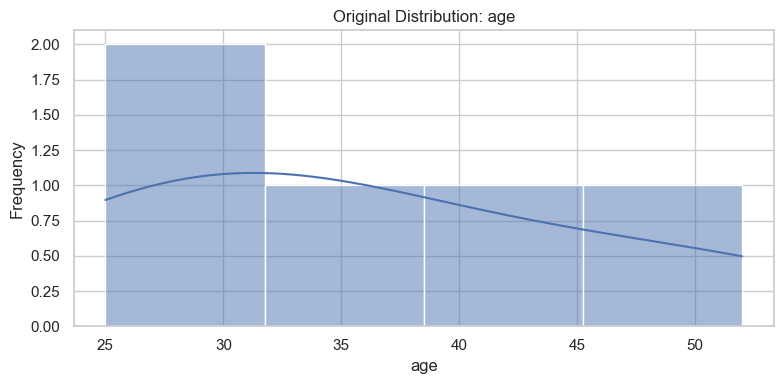

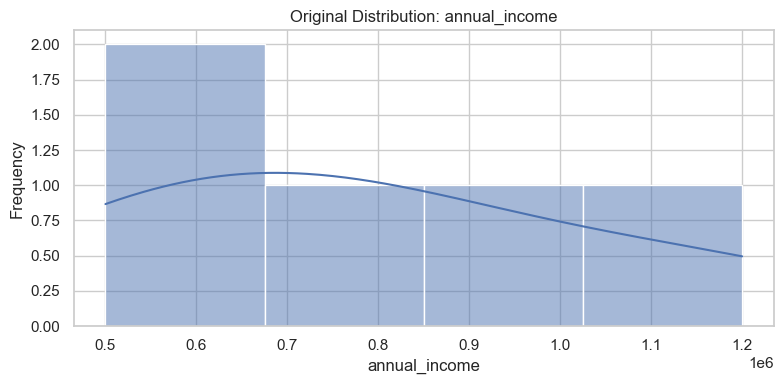

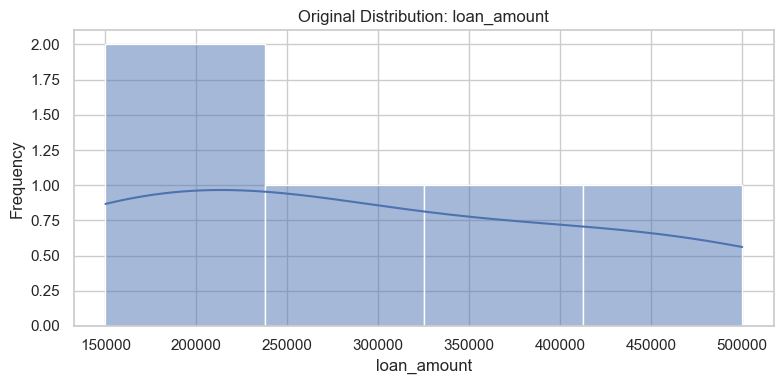

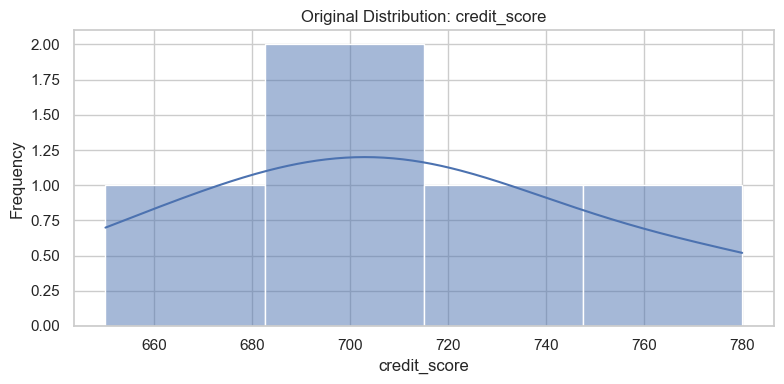

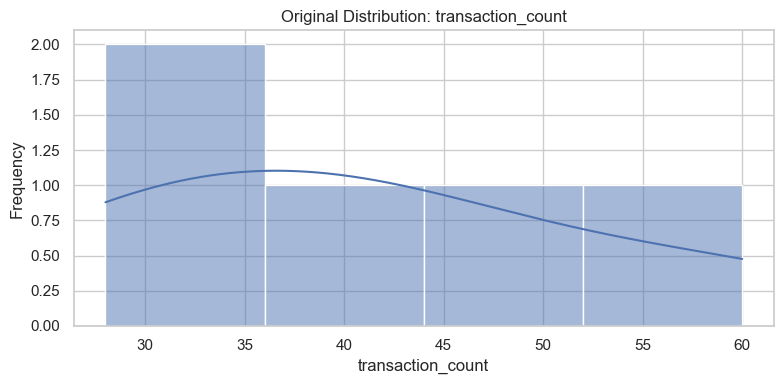

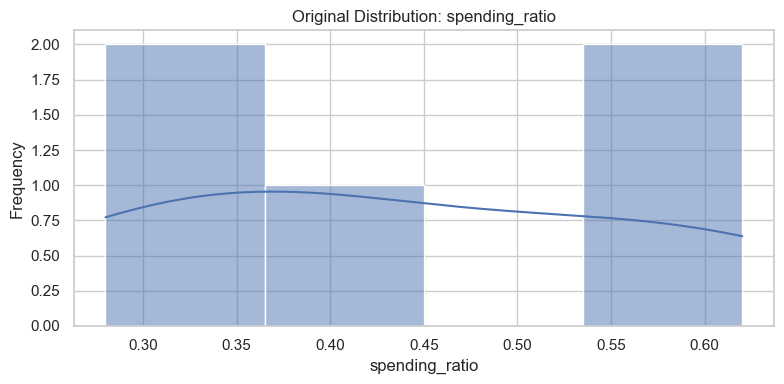

In [5]:
display(df[numeric_features].describe().T)

skew_before = df[numeric_features].skew(numeric_only=True).rename("skewness_before")
display(skew_before.to_frame())

for column in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[column].dropna(), kde=True)
    plt.title(f"Original Distribution: {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

## 6. FunctionTransformer

`FunctionTransformer` applies a user-defined function to data. It is useful when a project needs a specific mathematical operation that is not directly represented by a dedicated transformer.

The example below uses a square-root transformation. It is defined only for non-negative values, so the notebook checks the input domain before applying it. The original DataFrame is not modified.

In [9]:
sqrt_transformer = FunctionTransformer(
    np.sqrt,
    feature_names_out="one-to-one"
)

sqrt_results = {}

for column, transformed_values in sqrt_results.items():

    print(f"\nFeature: {column}")

    comparison = pd.DataFrame({
        "Original": df.loc[
            df[column].notna(), column
        ].values[:5],

        "Square_Root": transformed_values[:5]
    })

    display(comparison)

**Interpretation:** The square-root function can reduce right skewness for some non-negative variables. It cannot be applied directly to negative values in the real number domain. Always inspect the feature's minimum before selecting a transformation.

## 7. Log Transformation

A natural logarithm can reduce right skewness and compress large values. The standard `log(x)` requires strictly positive values. For non-negative data, `log1p(x)` calculates `log(1 + x)` and can handle zero, but not values below zero.

The following example applies the natural log only to columns whose non-missing values are strictly positive.

In [10]:
log_results = {}

for column in numeric_features:
    values = df[column].dropna()
    if (values > 0).all():
        log_results[column] = np.log(values)
    else:
        print(
            f"Skipped {column}: natural log requires all values to be greater than zero. "
            f"Minimum observed value = {values.min()}"
        )

print("Log-transformed columns:", list(log_results.keys()))

Log-transformed columns: ['age', 'annual_income', 'loan_amount', 'credit_score', 'transaction_count', 'spending_ratio']


**Interpretation:** Log transformation compresses large positive values more strongly than small values. It is often considered for right-skewed financial variables such as income or loan amount, provided the values are positive. The transformed values are on a logarithmic scale and are no longer expressed in the original currency units.

## 8. Reciprocal Transformation

The reciprocal transformation is defined as `1 / x`. It can substantially change the shape of a distribution, but it is undefined at zero and may reverse the ordering of positive values.

This notebook applies it only to features whose non-missing values are all non-zero. Review the resulting distribution carefully before using this transformation in a model.

In [11]:
reciprocal_results = {}

for column in numeric_features:
    values = df[column].dropna()
    if (values != 0).all():
        reciprocal_results[column] = 1 / values
    else:
        print(f"Skipped {column}: reciprocal transformation is undefined at zero.")

print("Reciprocal-transformed columns:", list(reciprocal_results.keys()))

Reciprocal-transformed columns: ['age', 'annual_income', 'loan_amount', 'credit_score', 'transaction_count', 'spending_ratio']


**Interpretation:** Reciprocal transformation is less commonly used as a general-purpose preprocessing step. It can magnify values close to zero and may create unstable results. Use it only when the mathematical form is justified by the analytical problem.

## 9. Box-Cox Transformation

The Box-Cox transformation is a power transformation designed for strictly positive values. It estimates a parameter, lambda (λ), from the data.

- It requires every input value to be strictly positive.
- It can reduce skewness and help stabilize variance.
- The estimated lambda depends on the data used to fit it.
- For predictive modelling, estimate lambda using training data only.

This section demonstrates Box-Cox on eligible columns. Missing values are excluded from the individual feature demonstration; they are not imputed.

In [12]:
boxcox_results = {}
boxcox_lambdas = {}

for column in numeric_features:
    values = df[column].dropna().astype(float)

    if len(values) < 2:
        print(f"Skipped {column}: insufficient non-missing observations.")
        continue

    if (values > 0).all():
        transformer = PowerTransformer(method="box-cox", standardize=False)
        transformed = transformer.fit_transform(values.to_frame()).ravel()
        boxcox_results[column] = transformed
        boxcox_lambdas[column] = float(transformer.lambdas_[0])
    else:
        print(f"Skipped {column}: Box-Cox requires strictly positive values.")

print("Estimated Box-Cox lambda values:")
display(pd.Series(boxcox_lambdas, name="lambda").to_frame())

Estimated Box-Cox lambda values:


,lambda
age,-0.814414
annual_income,-0.372432
loan_amount,-0.245936
credit_score,-1.652931
transaction_count,-0.599749
spending_ratio,-0.002234


**Interpretation:** A lambda near 1 indicates a transformation relatively close to the original scale. Other lambda values imply a stronger power transformation. Box-Cox cannot be used directly when a feature contains zero or negative values. Do not add an arbitrary constant without a documented reason.

## 10. Yeo-Johnson Transformation

Yeo-Johnson is another power transformation. Unlike Box-Cox, it can handle positive, zero, and negative values. It estimates a lambda parameter and can be useful when a feature's domain includes zero or negative observations.

The demonstration below fits one transformer per eligible feature using its non-missing observations. The later modelling pipeline demonstrates the correct training-only fitting approach.

In [13]:
yeojohnson_results = {}
yeojohnson_lambdas = {}

for column in numeric_features:
    values = df[column].dropna().astype(float)

    if len(values) < 2 or values.nunique() < 2:
        print(f"Skipped {column}: insufficient variation for power transformation.")
        continue

    transformer = PowerTransformer(method="yeo-johnson", standardize=False)
    transformed = transformer.fit_transform(values.to_frame()).ravel()

    yeojohnson_results[column] = transformed
    yeojohnson_lambdas[column] = float(transformer.lambdas_[0])

print("Estimated Yeo-Johnson lambda values:")
display(pd.Series(yeojohnson_lambdas, name="lambda").to_frame())

Estimated Yeo-Johnson lambda values:


,lambda
age,-0.857844
annual_income,-0.372433
loan_amount,-0.245939
credit_score,-1.656558
transaction_count,-0.632964
spending_ratio,-1.506662


**Interpretation:** Yeo-Johnson is more flexible with respect to the input domain than Box-Cox. It does not mean that every feature should be transformed. Compare the original and transformed distributions and retain a transformation only when it is analytically justified.

## 11. PowerTransformer: Box-Cox and Yeo-Johnson comparison

Scikit-learn's `PowerTransformer` supports both Box-Cox and Yeo-Johnson methods. By default, it standardizes transformed values to zero mean and unit variance. In this section, `standardize=False` is used so that the focus remains on the power transformation itself.

In [14]:
power_comparison = pd.DataFrame({
    "feature": numeric_features,
    "minimum": [df[col].min() for col in numeric_features],
    "maximum": [df[col].max() for col in numeric_features],
    "skewness_before": [df[col].skew() for col in numeric_features],
    "kurtosis_before": [df[col].kurt() for col in numeric_features],
    "box_cox_lambda": [boxcox_lambdas.get(col, np.nan) for col in numeric_features],
    "yeo_johnson_lambda": [yeojohnson_lambdas.get(col, np.nan) for col in numeric_features]
})

display(power_comparison)

,feature,minimum,maximum,skewness_before,kurtosis_before,box_cox_lambda,yeo_johnson_lambda
0,age,25.00,52.00,0.851417,-0.128166,-0.814414,-0.857844
1,annual_income,500000.00,1200000.00,0.782104,0.066006,-0.372432,-0.372433
2,loan_amount,150000.00,500000.00,0.604887,-1.760915,-0.245936,-0.245939
3,credit_score,650.00,780.00,0.468486,1.170370,-1.652931,-1.656558
4,transaction_count,28.00,60.00,0.846379,0.402978,-0.599749,-0.632964
5,spending_ratio,0.28,0.62,0.336252,-1.970829,-0.002234,-1.506662


## 12. Compare original and transformed distributions

The following helper function compares the original values with a transformed result using histograms. It also calculates skewness before and after transformation. Results are shown only for observations that were eligible for the selected transformation.

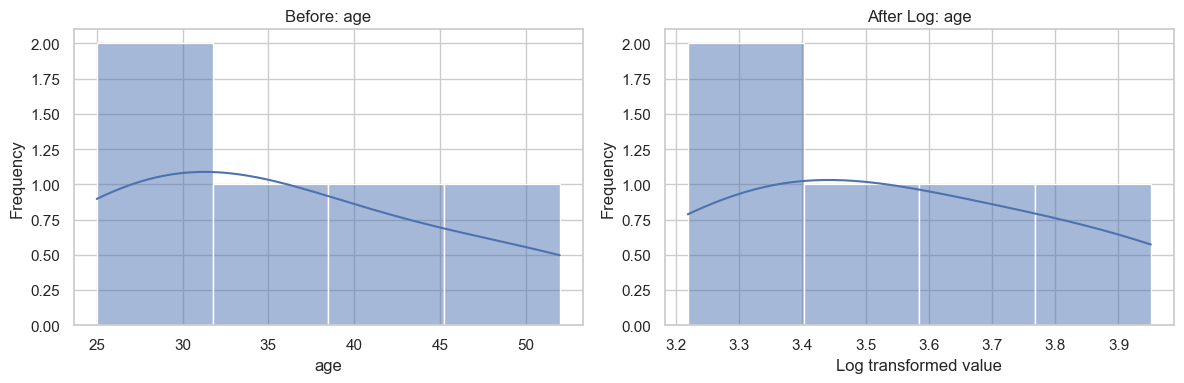

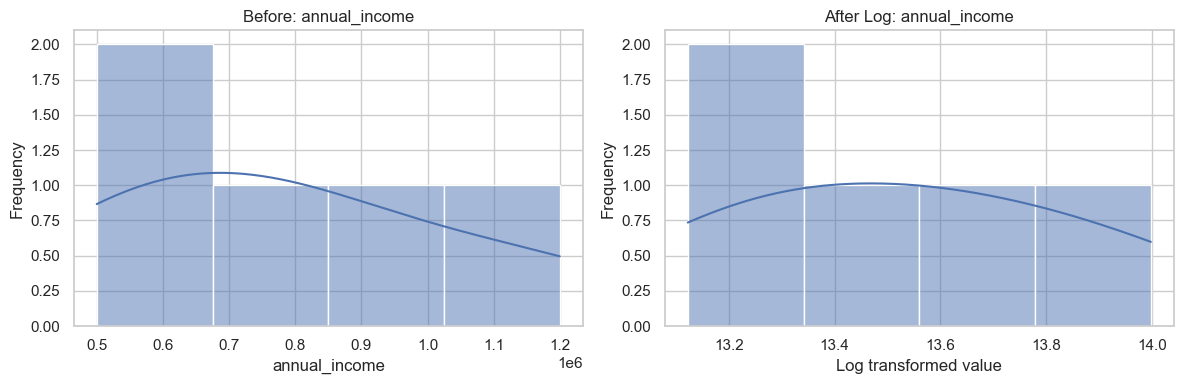

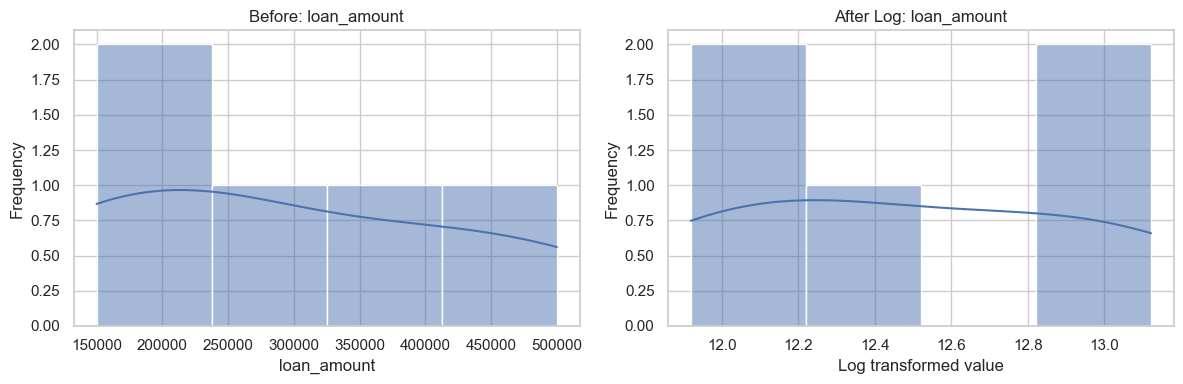

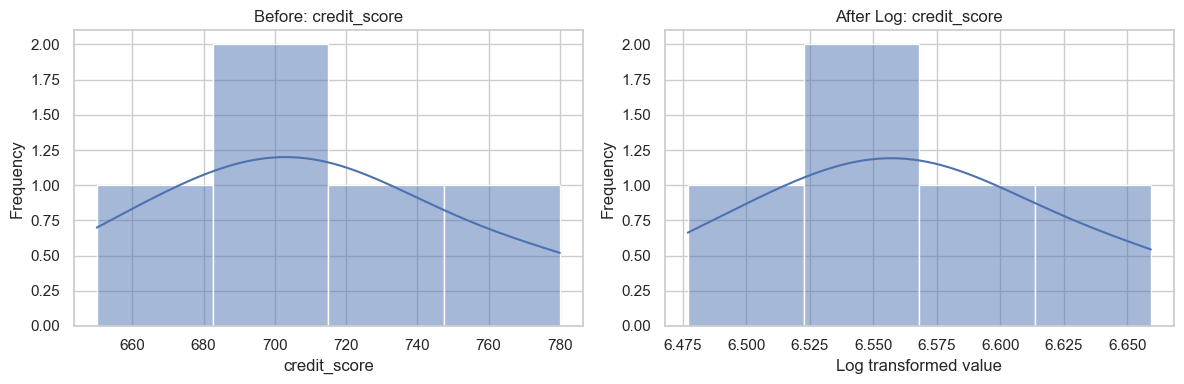

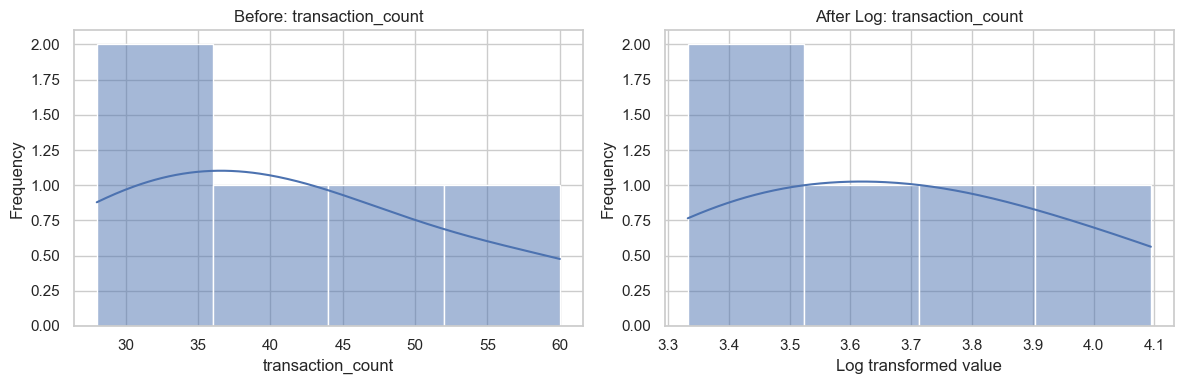

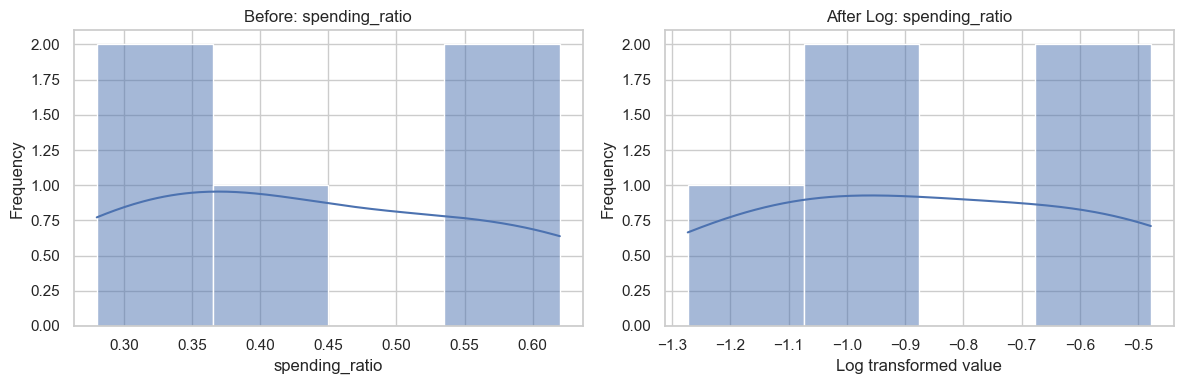

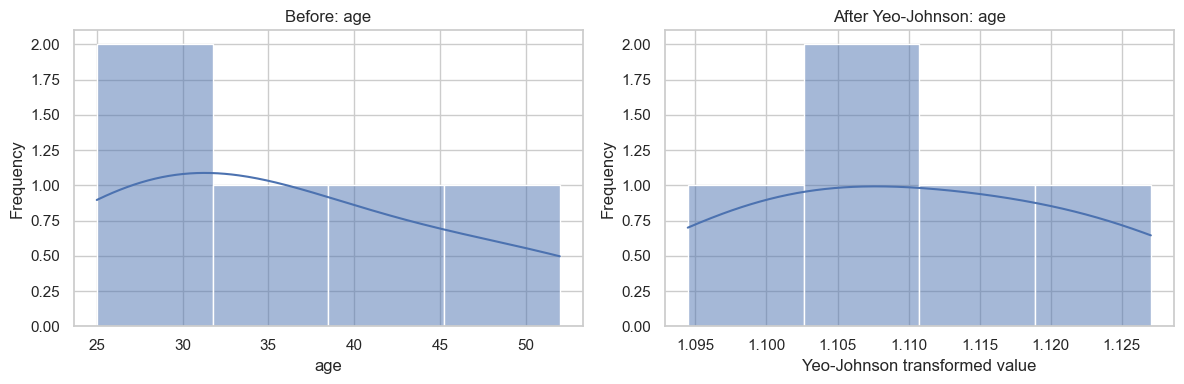

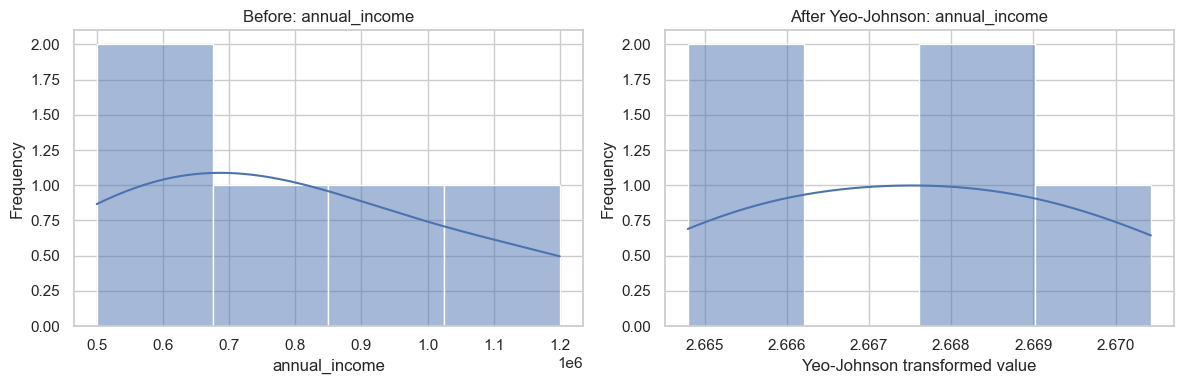

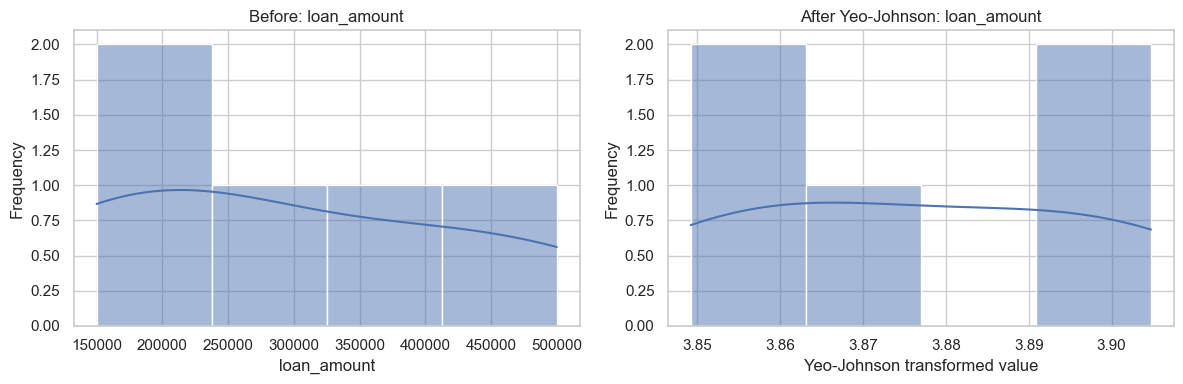

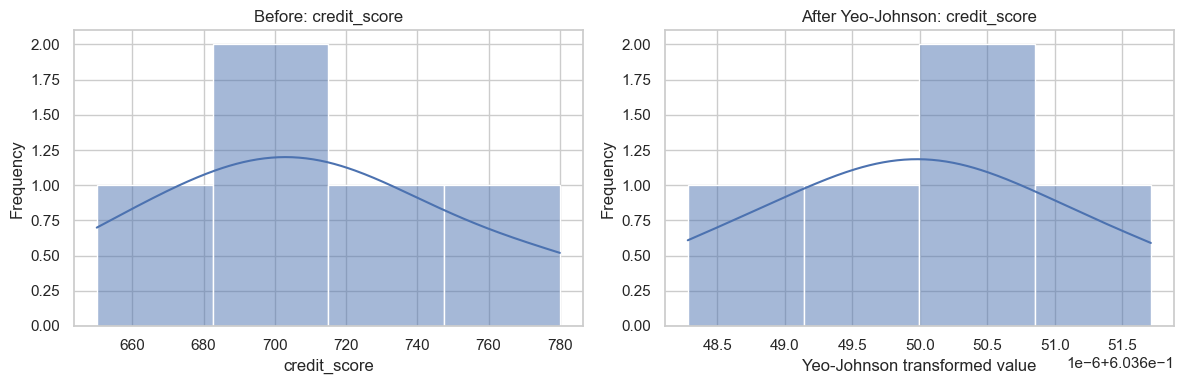

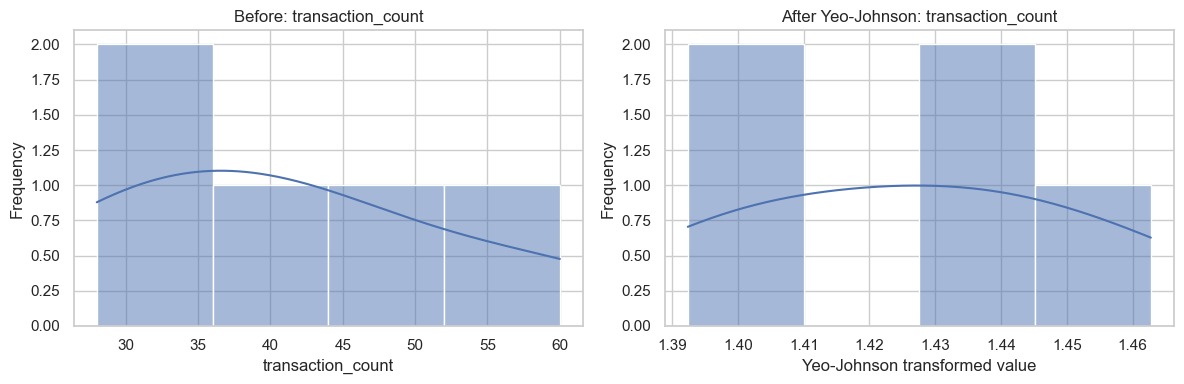

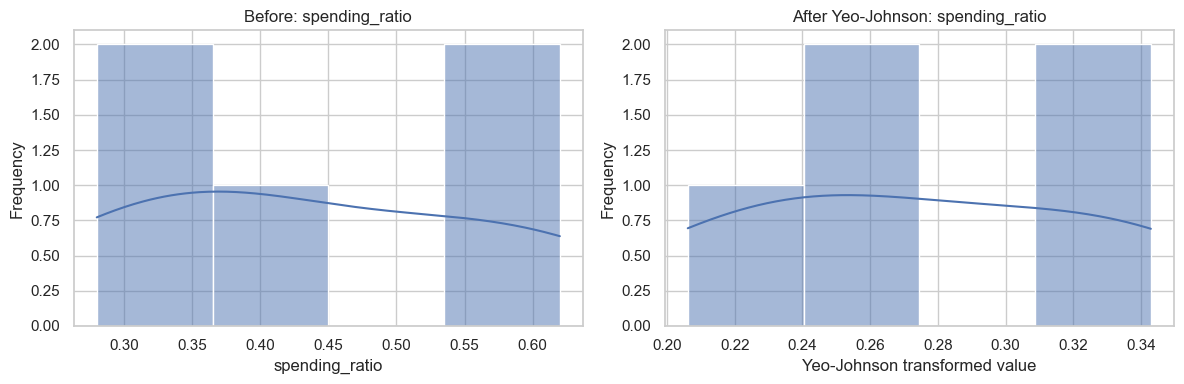

,feature,method,skewness_before,skewness_after,kurtosis_before,kurtosis_after
0,age,Log,0.851417,0.465622,-0.128166,-0.843033
1,annual_income,Log,0.782104,0.264803,0.066006,-0.805533
2,loan_amount,Log,0.604887,0.195035,-1.760915,-2.248648
3,credit_score,Log,0.468486,0.307682,1.170370,1.059442
4,transaction_count,Log,0.846379,0.376452,0.402978,-0.575359
5,spending_ratio,Log,0.336252,0.001287,-1.970829,-1.737236
6,age,Yeo-Johnson,0.851417,0.139852,-0.128166,-1.100910
7,annual_income,Yeo-Johnson,0.782104,0.070506,0.066006,-0.964359
8,loan_amount,Yeo-Johnson,0.604887,0.088174,-1.760915,-2.265023
9,credit_score,Yeo-Johnson,0.468486,0.000000,1.170370,0.000000


In [15]:
def compare_distribution(original_values, transformed_values, feature_name, method_name):
    original_values = pd.Series(original_values).dropna()
    transformed_values = pd.Series(transformed_values).dropna()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(original_values, kde=True, ax=axes[0])
    axes[0].set_title(f"Before: {feature_name}")
    axes[0].set_xlabel(feature_name)
    axes[0].set_ylabel("Frequency")

    sns.histplot(transformed_values, kde=True, ax=axes[1])
    axes[1].set_title(f"After {method_name}: {feature_name}")
    axes[1].set_xlabel(f"{method_name} transformed value")
    axes[1].set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

    return {
        "feature": feature_name,
        "method": method_name,
        "skewness_before": original_values.skew(),
        "skewness_after": transformed_values.skew(),
        "kurtosis_before": original_values.kurt(),
        "kurtosis_after": transformed_values.kurt()
    }

comparison_rows = []

for column, transformed in sqrt_results.items():
    comparison_rows.append(
        compare_distribution(df[column].dropna(), transformed, column, "Square Root")
    )

for column, transformed in log_results.items():
    comparison_rows.append(
        compare_distribution(df[column].dropna(), transformed, column, "Log")
    )

for column, transformed in yeojohnson_results.items():
    comparison_rows.append(
        compare_distribution(df[column].dropna(), transformed, column, "Yeo-Johnson")
    )

transformation_comparison = pd.DataFrame(comparison_rows)
display(transformation_comparison)

**Interpretation:** Compare the shape and skewness values rather than assuming a transformation is better. A reduction in absolute skewness can be useful for some modelling methods, but it is not a universal selection rule. Also consider interpretability and model validation performance.

## 13. ColumnTransformer

`ColumnTransformer` applies different transformations to different column groups within one preprocessing object. This is useful when a dataset contains multiple numerical features that need different treatment.

The following example builds a reusable preprocessing transformer:
- `PowerTransformer(method="yeo-johnson")` for selected continuous numerical features.
- `StandardScaler` for selected count-like numerical features.
- Unspecified columns are dropped from this demonstration transformer.

The target and customer identifier are excluded. Select columns based on the actual dataset and document the rationale.

In [16]:
# Example feature groups. Review these selections against your dataset's meaning.
continuous_candidates = [
    col for col in ["annual_income", "loan_amount", "spending_ratio", "credit_score", "age"]
    if col in numeric_features
]

count_candidates = [
    col for col in ["transaction_count"]
    if col in numeric_features
]

# Avoid assigning a column to more than one transformer.
count_candidates = [col for col in count_candidates if col not in continuous_candidates]

print("Yeo-Johnson columns:", continuous_candidates)
print("Standard-scaled columns:", count_candidates)

transformer_steps = []

if continuous_candidates:
    transformer_steps.append((
        "yeo_johnson",
        PowerTransformer(method="yeo-johnson", standardize=False),
        continuous_candidates
    ))

if count_candidates:
    transformer_steps.append((
        "standard_scaler",
        StandardScaler(),
        count_candidates
    ))

if not transformer_steps:
    raise ValueError("No suitable numeric columns were selected for ColumnTransformer.")

column_transformer = ColumnTransformer(
    transformers=transformer_steps,
    remainder="drop",
    verbose_feature_names_out=True
)

print(column_transformer)

Yeo-Johnson columns: ['annual_income', 'loan_amount', 'spending_ratio', 'credit_score', 'age']
Standard-scaled columns: ['transaction_count']
ColumnTransformer(transformers=[('yeo_johnson',
                                 PowerTransformer(standardize=False),
                                 ['annual_income', 'loan_amount',
                                  'spending_ratio', 'credit_score', 'age']),
                                ('standard_scaler', StandardScaler(),
                                 ['transaction_count'])])


## 14. Prevent data leakage: fit transformations on training data only

A transformation that estimates parameters from data must be fitted on the training subset only. The test subset is transformed using the parameters learned from training data.

This example:
1. Separates features (`X`) from the target (`y`).
2. Splits the data into training and test subsets.
3. Fits the `ColumnTransformer` on training features only.
4. Applies the fitted transformer to the test features.

Rows with missing values in selected columns may cause some transformations to fail. The project should use the imputed dataset produced on Day 3 before running the final pipeline. This example reports missingness before fitting and stops with a clear message if selected columns still contain missing values.

In [17]:
selected_transform_columns = continuous_candidates + count_candidates

X = df.drop(columns=[col for col in ID_COLUMNS if col in df.columns] + [TARGET_COLUMN])
y = df[TARGET_COLUMN]

# Use stratification to preserve target class proportions where possible.
# Stratification requires at least two observations in each class and enough
# test rows to represent every class. Small teaching datasets may not qualify.
class_counts = y.value_counts(dropna=True)
can_stratify = (
    y.notna().all()
    and y.nunique() == 2
    and class_counts.min() >= 2
    and int(np.ceil(0.20 * len(y))) >= y.nunique()
)
stratify_values = y if can_stratify else None
if not can_stratify:
    print("Stratification skipped: dataset is too small or class counts are insufficient.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_values
)

missing_train = X_train[selected_transform_columns].isna().sum()
missing_test = X_test[selected_transform_columns].isna().sum()

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nMissing values in selected training columns:")
display(missing_train.to_frame("missing_train"))
print("\nMissing values in selected test columns:")
display(missing_test.to_frame("missing_test"))

if missing_train.sum() > 0 or missing_test.sum() > 0:
    print(
        "Transformation fitting not run: selected columns contain missing values. "
        "Use the imputed dataset from Day 3 and rerun this section."
    )
else:
    column_transformer.fit(X_train)
    X_train_transformed = column_transformer.transform(X_train)
    X_test_transformed = column_transformer.transform(X_test)

    print("Training transformed shape:", X_train_transformed.shape)
    print("Test transformed shape:", X_test_transformed.shape)
    print("ColumnTransformer fitted on training data only.")

Stratification skipped: dataset is too small or class counts are insufficient.
Training rows: 4
Test rows: 1

Missing values in selected training columns:


,missing_train
annual_income,0
loan_amount,0
spending_ratio,0
credit_score,0
age,0
transaction_count,0



Missing values in selected test columns:


,missing_test
annual_income,0
loan_amount,0
spending_ratio,0
credit_score,0
age,0
transaction_count,0


Training transformed shape: (4, 6)
Test transformed shape: (1, 6)
ColumnTransformer fitted on training data only.


## 15. Build a reusable transformation pipeline

A scikit-learn `Pipeline` chains transformations so that the same fitted operations are consistently applied to training and test data. The pipeline below demonstrates Yeo-Johnson followed by StandardScaler for selected numerical columns.

The pipeline is fitted only on training data. Do not include the target variable or identifier columns in the transformation pipeline.

In [18]:
if selected_transform_columns:
    numeric_pipeline = Pipeline(steps=[
        ("yeo_johnson", PowerTransformer(method="yeo-johnson")),
        ("scaler", StandardScaler())
    ])

    pipeline_preprocessor = ColumnTransformer(
        transformers=[
            ("numeric_pipeline", numeric_pipeline, selected_transform_columns)
        ],
        remainder="drop"
    )

    if X_train[selected_transform_columns].isna().sum().sum() == 0:
        pipeline_preprocessor.fit(X_train)
        train_pipeline_output = pipeline_preprocessor.transform(X_train)
        test_pipeline_output = pipeline_preprocessor.transform(X_test)

        print("Pipeline training output shape:", train_pipeline_output.shape)
        print("Pipeline test output shape:", test_pipeline_output.shape)
        print("Pipeline fitted on training data only.")
    else:
        print("Pipeline not fitted because selected training features contain missing values.")
else:
    print("No numerical feature columns are available for the pipeline.")

Pipeline training output shape: (4, 6)
Pipeline test output shape: (1, 6)
Pipeline fitted on training data only.


## 16. Transformation method summary

| Method | Handles zero? | Handles negative values? | Main consideration |
|---|---:|---:|---|
| Square root (`FunctionTransformer`) | Yes | No | Requires non-negative input |
| Natural log | No | No | Requires strictly positive input |
| `log1p` | Yes | No | Requires values greater than or equal to zero |
| Reciprocal | No | Yes, except zero | Undefined at zero; can magnify values near zero |
| Box-Cox | No | No | Requires strictly positive input |
| Yeo-Johnson | Yes | Yes | Estimates a power parameter |
| `ColumnTransformer` | Depends on its component transformers | Depends on its component transformers | Applies different transformations to selected columns |

`ColumnTransformer` is a composition tool, not a mathematical transformation by itself.

## 17. Export transformation comparison results

The following export contains only comparison statistics, not a replacement for the raw dataset. It is safe to rerun because it writes to the reports folder.

In [19]:
comparison_path = REPORTS_DIR / "day_07_transformation_comparison.csv"
lambda_path = REPORTS_DIR / "day_07_power_transformer_lambdas.csv"

if not transformation_comparison.empty:
    transformation_comparison.to_csv(comparison_path, index=False)
    print("Transformation comparison saved:", comparison_path.resolve())
else:
    print("No eligible log or Yeo-Johnson comparison results were available.")

power_comparison.to_csv(lambda_path, index=False)
print("Power transformation parameter summary saved:", lambda_path.resolve())

Transformation comparison saved: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\reports\day_07_transformation_comparison.csv
Power transformation parameter summary saved: C:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\reports\day_07_power_transformer_lambdas.csv


## 18. Day 07 conclusion

This notebook demonstrated custom transformations, logarithmic and reciprocal transformations, Box-Cox and Yeo-Johnson power transformations, distribution comparison, and the use of `ColumnTransformer` and `Pipeline`.

The most appropriate transformation should be selected feature by feature. The decision should consider the feature's valid domain, distribution, business meaning, model requirements, and validation performance.

**Data leakage prevention:** Any transformation that estimates parameters from data must be fitted on training data only. The test data must only be transformed using the fitted training transformer.

**Data integrity:** This notebook does not overwrite the original raw dataset. It exports comparison reports only.